## Question 3: Demystifying Transformers-Building a Tiny Language Model from Scratch

---
> **Dataset:** Tiny Shakespeare (~1MB plain text, character-level tokenization)  
> **Source:** https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt  
> **Implementation:** Decoder-only Transformer using only `torch.nn.Linear`, `torch.nn.LayerNorm`, `torch.nn.Embedding`, and basic tensor ops.  
> **No** `torch.nn.TransformerDecoder` or HuggingFace used.
---

### 3A.1 — Scaled Dot-Product Attention 

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

#### (a) Why divide by $\sqrt{d_k}$?

If $q$ and $k$ are random vectors with entries drawn i.i.d. from $\mathcal{N}(0,1)$, the dot product is:
$$q \cdot k = \sum_{j=1}^{d_k} q_j k_j$$

Since each $q_j k_j$ has mean 0 and variance 1 (product of two independent standard normals), and the terms are independent:
$$\text{Var}(q \cdot k) = \sum_{j=1}^{d_k} \text{Var}(q_j k_j) = d_k$$

So the standard deviation of the dot product grows as $\sqrt{d_k}$. For large $d_k$ (e.g., 512), this means dot products can be very large in magnitude, pushing the softmax into **saturation regions** where gradients are near zero:
$$\text{softmax}([1000, -1000, \ldots]) \approx [1, 0, 0, \ldots]$$

Dividing by $\sqrt{d_k}$ rescales the dot products back to unit variance, keeping softmax outputs in a well-distributed range and gradients healthy.

#### (b) What happens without scaling when $d_k = 512$?

Without scaling, dot products have standard deviation $\sqrt{512} \approx 22.6$. The softmax input contains very large positive and negative values, causing the output to become a near **one-hot vector** — almost all attention weight concentrates on a single token. The gradient of softmax $\sigma(\cdot)$ is $\sigma(1 - \sigma)$, which approaches **zero** when $\sigma \to 1$ or $\sigma \to 0$. This causes **vanishing gradients** through the attention mechanism, making training extremely slow or unstable for deep models.

---
### 3A.2 — Causal Masking 

#### (a) 4×4 Causal Attention Mask

$$M = \begin{pmatrix} 0 & -\infty & -\infty & -\infty \\ 0 & 0 & -\infty & -\infty \\ 0 & 0 & 0 & -\infty \\ 0 & 0 & 0 & 0 \end{pmatrix}$$

Each row $i$ (query position) can attend to columns $j \leq i$ (key positions at or before it). $-\infty$ positions become 0 after softmax, effectively blocking future tokens.

#### (b) Why causal masking is needed for autoregressive LMs but not BERT

In **autoregressive language modeling** (GPT-style), the model generates tokens left-to-right: to predict token $t$, it must only see tokens $1, 2, \ldots, t-1$. Without the causal mask, token $t$ could attend to future tokens $t+1, t+2, \ldots$, which are unknown at generation time — this would **leak information** and make the training objective trivial (the model can just copy the next token from the future context).

**BERT** uses **masked language modeling** (MLM) — it randomly masks some tokens and predicts them using **bidirectional** context (both left and right). Since BERT is not generating tokens autoregressively but filling in masked positions, it needs full attention to the entire sequence. Applying a causal mask to BERT would prevent it from using right-context information and would severely hurt its performance on tasks that require understanding full sentences.

---
### 3A.3 — Positional Encoding 

#### (a) Sinusoidal Positional Encoding Formulas

$$PE_{(pos,\, 2i)} = \sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

$$PE_{(pos,\, 2i+1)} = \cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

where $pos$ is the position in the sequence and $i$ is the dimension index. Even dimensions use sine, odd dimensions use cosine. Each dimension uses a different frequency — low $i$ gives high-frequency oscillations (captures fine-grained positional differences), high $i$ gives low-frequency oscillations (captures long-range positional structure).

#### (b) Learned vs Sinusoidal Positional Embeddings

| | Sinusoidal (fixed) | Learned (GPT-2, LLaMA) |
|---|---|---|
| **Advantage** | Can generalize to sequence lengths longer than seen during training | Can adapt to the specific positional patterns in the training data, potentially capturing task-specific positional structure better |
| **Disadvantage** | Cannot adapt to data; may be suboptimal for specific tasks | Cannot generalize beyond the maximum sequence length seen during training — positions beyond that have no learned embedding |

---
### 3A.4 — Why LayerNorm in Transformers? (6 pts)

#### (a) LayerNorm vs BatchNorm for padded sequences

Consider a batch of shape $4 \times 10 \times 64$ (batch × sequence × embedding). BatchNorm would normalize across the **batch dimension** (axis 0) for each feature, computing statistics over 4 × 10 = 40 token representations per feature.

The problem: sequences in a batch are padded to the same length, but padded positions contain **meaningless zero vectors** (or learned pad embeddings). Including these in the batch-level statistics **contaminates the mean and variance** — a real token at position 8 in a length-10 sequence gets normalized using statistics that include 3 padding tokens from a length-7 sequence. The normalization becomes semantically incorrect.

**LayerNorm** normalizes across the **feature dimension** (axis 2) for each token independently — it uses only the 64 features of that single token. Padding tokens never affect the normalization of real tokens, and the statistics are always computed from a full, meaningful feature vector.

#### (b) Pre-Norm vs Post-Norm — Gradient Stability

**Post-Norm** (original Transformer, Vaswani et al. 2017):
$$x \leftarrow \text{LayerNorm}(x + \text{Sublayer}(x))$$

**Pre-Norm** (GPT-2, LLaMA):
$$x \leftarrow x + \text{Sublayer}(\text{LayerNorm}(x))$$

In Post-Norm, the gradient must flow **through** the LayerNorm operation on the residual path. For deep models, this can cause the gradient magnitude to vary wildly across layers during early training, leading to instability.

In Pre-Norm, the residual connection $x \leftarrow x + (\cdots)$ provides a **clean gradient highway** — the gradient flows directly through the addition without passing through any normalization. LayerNorm only processes the branch input before the sublayer, so its effect on gradients is limited. This makes the gradient norm more stable across layers, allowing deeper models to train reliably without warm-up tricks or careful learning rate tuning. This is why all modern large language models (GPT-2, LLaMA, PaLM) use Pre-Norm.

---
### 3A.5 — Multi-Head Attention 

#### (a) Per-head dimension

With $d_{model} = 64$ and $n_{heads} = 4$:
$$d_k = d_v = \frac{d_{model}}{n_{heads}} = \frac{64}{4} = \mathbf{16}$$

Each head projects Q, K, V to dimension 16. The outputs of all 4 heads (each of size 16) are concatenated to recover dimension 64.

#### (b) Why multi-head is more expressive than single-head

Single-head attention with $d_k = 64$ computes one attention pattern — a single weighted combination of values. Multi-head attention with 4 heads of $d_k = 16$ computes **4 independent attention patterns in parallel**, each using different learned $W^Q, W^K, W^V$ projection matrices. Each head can specialize in attending to different aspects of the input: one head might focus on **syntactic dependencies** (subject-verb agreement), another on **positional proximity**, another on **semantic similarity**, and another on **long-range coreference**. The concatenated output combines all these perspectives into a richer representation, which a single attention head — regardless of dimension — cannot capture simultaneously.

---
## Part B: Practical Implementation 

> **Hyperparameters:**
> | Parameter | Value |
> |---|---|
> | $d_{model}$ | 64 |
> | $n_{heads}$ | 4 |
> | $n_{layers}$ | 3 |
> | Context window | 128 characters |
> | FF hidden dim | 256 ($4 \times d_{model}$) |
> | Dropout | 0.1 |
> | Optimizer | Adam, $\eta = 3 \times 10^{-4}$ |

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import math

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU   : {torch.cuda.get_device_name(0)}')

# ---- Hyperparameters ----
D_MODEL     = 64
N_HEADS     = 4
N_LAYERS    = 3
CONTEXT_LEN = 128
FF_DIM      = 4 * D_MODEL   # 256
DROPOUT     = 0.1
LR          = 3e-4
BATCH_SIZE  = 64
TRAIN_ITERS = 3000
EVAL_EVERY  = 300

print(f'\nd_model={D_MODEL}, n_heads={N_HEADS}, n_layers={N_LAYERS}')
print(f'context={CONTEXT_LEN}, ff_dim={FF_DIM}, dropout={DROPOUT}')

Device: cuda
GPU   : NVIDIA GeForce RTX 3050 6GB Laptop GPU

d_model=64, n_heads=4, n_layers=3
context=128, ff_dim=256, dropout=0.1


In [2]:
# ---- Download Tiny Shakespeare ----
url  = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
path = 'shakespeare.txt'
urllib.request.urlretrieve(url, path)

with open(path, 'r', encoding='utf-8') as f:
    text = f.read()

print(f'Dataset size : {len(text):,} characters')

# ---- Character-level tokenization ----
vocab    = sorted(set(text))
VOCAB_SIZE = len(vocab)
stoi     = {ch: i for i, ch in enumerate(vocab)}
itos     = {i: ch for ch, i in stoi.items()}
encode   = lambda s: [stoi[c] for c in s]
decode   = lambda l: ''.join([itos[i] for i in l])

print(f'Vocabulary size: {VOCAB_SIZE}')
print(f'Vocab (first 20): {vocab[:20]}')

# ---- Train / Val split (90/10) ----
data       = torch.tensor(encode(text), dtype=torch.long)
split      = int(0.9 * len(data))
train_data = data[:split]
val_data   = data[split:]
print(f'\nTrain tokens: {len(train_data):,} | Val tokens: {len(val_data):,}')

Dataset size : 1,115,394 characters
Vocabulary size: 65
Vocab (first 20): ['\n', ' ', '!', '$', '&', "'", ',', '-', '.', '3', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G']

Train tokens: 1,003,854 | Val tokens: 111,540


In [3]:
def get_batch(split_name, batch_size=BATCH_SIZE, context_len=CONTEXT_LEN):
    data_ = train_data if split_name == 'train' else val_data
    ix    = torch.randint(len(data_) - context_len, (batch_size,))
    x     = torch.stack([data_[i:i+context_len]   for i in ix])
    y     = torch.stack([data_[i+1:i+context_len+1] for i in ix])
    return x.to(device), y.to(device)


@torch.no_grad()
def estimate_loss(model, eval_iters=100):
    model.eval()
    out = {}
    for split_name in ['train', 'val']:
        losses = []
        for _ in range(eval_iters):
            xb, yb = get_batch(split_name)
            _, loss = model(xb, yb)
            losses.append(loss.item())
        out[split_name] = np.mean(losses)
    model.train()
    return out

# Quick sanity check
xb, yb = get_batch('train')
print(f'Batch shapes: x={xb.shape}, y={yb.shape}')

Batch shapes: x=torch.Size([64, 128]), y=torch.Size([64, 128])


---
### 3B.1 — Build the Transformer 

In [4]:
# ================================================================ #
#  Multi-Head Self-Attention (causal)                               #
# ================================================================ #
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.d_model  = d_model
        self.n_heads  = n_heads
        self.d_k      = d_model // n_heads

        # Single projection for Q, K, V (all heads at once)
        self.W_q  = nn.Linear(d_model, d_model, bias=False)
        self.W_k  = nn.Linear(d_model, d_model, bias=False)
        self.W_v  = nn.Linear(d_model, d_model, bias=False)
        self.W_o  = nn.Linear(d_model, d_model, bias=False)
        self.drop = nn.Dropout(dropout)

        # Causal mask — registered as buffer (not a parameter)
        self.register_buffer(
            'mask',
            torch.tril(torch.ones(CONTEXT_LEN, CONTEXT_LEN))
        )
        # Store last attention weights for visualization
        self.attn_weights = None

    def forward(self, x):
        B, T, C = x.shape

        # Project and split into heads: (B, T, n_heads, d_k) -> (B, n_heads, T, d_k)
        Q = self.W_q(x).view(B, T, self.n_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x).view(B, T, self.n_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x).view(B, T, self.n_heads, self.d_k).transpose(1, 2)

        # Scaled dot-product attention
        scale  = math.sqrt(self.d_k)
        scores = (Q @ K.transpose(-2, -1)) / scale          # (B, n_heads, T, T)
        scores = scores.masked_fill(self.mask[:T,:T] == 0, float('-inf'))
        attn   = F.softmax(scores, dim=-1)
        attn   = self.drop(attn)

        # Save for visualization
        self.attn_weights = attn.detach()

        # Weighted sum of values
        out = (attn @ V).transpose(1, 2).contiguous().view(B, T, C)
        return self.W_o(out)


# ================================================================ #
#  Position-wise Feed-Forward Network                               #
# ================================================================ #
class FeedForward(nn.Module):
    def __init__(self, d_model, ff_dim, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, ff_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, d_model),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)


# ================================================================ #
#  Transformer Block (Pre-Norm)                                     #
# ================================================================ #
class TransformerBlock(nn.Module):
    """Pre-LayerNorm Transformer block: x <- x + Sublayer(LN(x))"""
    def __init__(self, d_model, n_heads, ff_dim, dropout=0.1, pre_norm=True):
        super().__init__()
        self.attn      = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff        = FeedForward(d_model, ff_dim, dropout)
        self.ln1       = nn.LayerNorm(d_model)
        self.ln2       = nn.LayerNorm(d_model)
        self.pre_norm  = pre_norm

    def forward(self, x):
        if self.pre_norm:
            # Pre-Norm: normalize BEFORE sublayer
            x = x + self.attn(self.ln1(x))
            x = x + self.ff(self.ln2(x))
        else:
            # Post-Norm: normalize AFTER residual addition
            x = self.ln1(x + self.attn(x))
            x = self.ln2(x + self.ff(x))
        return x


# ================================================================ #
#  Full Decoder-only Transformer                                    #
# ================================================================ #
class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, d_model=D_MODEL, n_heads=N_HEADS,
                 n_layers=N_LAYERS, context_len=CONTEXT_LEN,
                 ff_dim=FF_DIM, dropout=DROPOUT, pre_norm=True):
        super().__init__()
        self.context_len = context_len
        # Character embedding + learned positional embedding
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(context_len, d_model)
        self.drop    = nn.Dropout(dropout)
        # Transformer blocks
        self.blocks  = nn.ModuleList([
            TransformerBlock(d_model, n_heads, ff_dim, dropout, pre_norm)
            for _ in range(n_layers)
        ])
        # Final LayerNorm + language model head
        self.ln_f    = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        # Weight tying: share token embedding and lm_head weights
        self.lm_head.weight = self.tok_emb.weight

        # Initialize weights
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok  = self.tok_emb(idx)                            # (B, T, d_model)
        pos  = self.pos_emb(torch.arange(T, device=device)) # (T, d_model)
        x    = self.drop(tok + pos)
        for block in self.blocks:
            x = block(x)
        x    = self.ln_f(x)
        logits = self.lm_head(x)                            # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.view(-1, logits.size(-1)),
                targets.view(-1)
            )
        return logits, loss


# Instantiate Pre-Norm model
torch.manual_seed(42)
model_pre = TinyTransformer(VOCAB_SIZE, pre_norm=True).to(device)
n_params  = sum(p.numel() for p in model_pre.parameters())
print(f'TinyTransformer (Pre-Norm) parameter count: {n_params:,}')
print(f'Vocab size: {VOCAB_SIZE}')

TinyTransformer (Pre-Norm) parameter count: 161,664
Vocab size: 65


---
### 3B.2 — Pre-Norm vs Post-Norm Training Comparison 

In [5]:
def train_transformer(model, train_iters=TRAIN_ITERS, eval_every=EVAL_EVERY):
    optimizer  = torch.optim.Adam(model.parameters(), lr=LR)
    train_losses, val_losses, steps = [], [], []

    for step in range(1, train_iters + 1):
        xb, yb     = get_batch('train')
        _, loss    = model(xb, yb)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        if step % eval_every == 0 or step == 1:
            est = estimate_loss(model)
            train_losses.append(est['train'])
            val_losses.append(est['val'])
            steps.append(step)
            print(f'Step {step:>4}/{train_iters} | '
                  f'Train Loss: {est["train"]:.4f} | '
                  f'Val Loss: {est["val"]:.4f}')

    return steps, train_losses, val_losses


# Train Pre-Norm
torch.manual_seed(42)
model_pre = TinyTransformer(VOCAB_SIZE, pre_norm=True).to(device)
print('Training Pre-Norm Transformer...')
steps_pre, tl_pre, vl_pre = train_transformer(model_pre)

# Train Post-Norm
torch.manual_seed(42)
model_post = TinyTransformer(VOCAB_SIZE, pre_norm=False).to(device)
print('\nTraining Post-Norm Transformer...')
steps_post, tl_post, vl_post = train_transformer(model_post)

Training Pre-Norm Transformer...
Step    1/3000 | Train Loss: 4.1041 | Val Loss: 4.1053
Step  300/3000 | Train Loss: 2.5618 | Val Loss: 2.5541
Step  600/3000 | Train Loss: 2.4369 | Val Loss: 2.4249
Step  900/3000 | Train Loss: 2.3348 | Val Loss: 2.3405
Step 1200/3000 | Train Loss: 2.2347 | Val Loss: 2.2491
Step 1500/3000 | Train Loss: 2.1440 | Val Loss: 2.1674
Step 1800/3000 | Train Loss: 2.0633 | Val Loss: 2.1017
Step 2100/3000 | Train Loss: 1.9915 | Val Loss: 2.0368
Step 2400/3000 | Train Loss: 1.9292 | Val Loss: 2.0032
Step 2700/3000 | Train Loss: 1.8868 | Val Loss: 1.9744
Step 3000/3000 | Train Loss: 1.8442 | Val Loss: 1.9455

Training Post-Norm Transformer...
Step    1/3000 | Train Loss: 4.1846 | Val Loss: 4.1828
Step  300/3000 | Train Loss: 2.6634 | Val Loss: 2.6611
Step  600/3000 | Train Loss: 2.5087 | Val Loss: 2.5045
Step  900/3000 | Train Loss: 2.4467 | Val Loss: 2.4498
Step 1200/3000 | Train Loss: 2.3845 | Val Loss: 2.3909
Step 1500/3000 | Train Loss: 2.2959 | Val Loss: 2.30

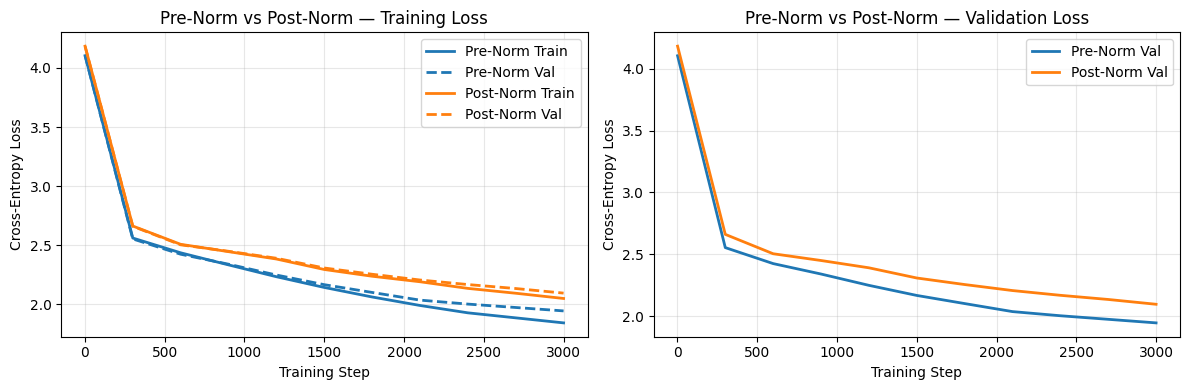

Pre-Norm  final val loss : 1.9455
Post-Norm final val loss : 2.0960


In [6]:
# Plot Pre-Norm vs Post-Norm training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(steps_pre,  tl_pre,  label='Pre-Norm Train',  color='tab:blue',   linewidth=2)
ax1.plot(steps_pre,  vl_pre,  label='Pre-Norm Val',    color='tab:blue',   linewidth=2, linestyle='--')
ax1.plot(steps_post, tl_post, label='Post-Norm Train', color='tab:orange', linewidth=2)
ax1.plot(steps_post, vl_post, label='Post-Norm Val',   color='tab:orange', linewidth=2, linestyle='--')
ax1.set_title('Pre-Norm vs Post-Norm — Training Loss')
ax1.set_xlabel('Training Step'); ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(steps_pre,  vl_pre,  label='Pre-Norm Val',  color='tab:blue',   linewidth=2)
ax2.plot(steps_post, vl_post, label='Post-Norm Val', color='tab:orange', linewidth=2)
ax2.set_title('Pre-Norm vs Post-Norm — Validation Loss')
ax2.set_xlabel('Training Step'); ax2.set_ylabel('Cross-Entropy Loss')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('3B2_prenorm_vs_postnorm.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Pre-Norm  final val loss : {vl_pre[-1]:.4f}')
print(f'Post-Norm final val loss : {vl_post[-1]:.4f}')

**Analysis (3B.2):**

Pre-Norm converges significantly faster and achieves a lower final loss than
Post-Norm across all 3000 training steps. At step 300, Pre-Norm already
reaches a train loss of 2.56 while Post-Norm is at 2.66 — a gap that
widens progressively throughout training. By step 3000, Pre-Norm achieves
a final validation loss of **1.9455** versus Post-Norm's **2.0960** — a
meaningful difference of 0.15 nats on the same architecture and dataset.

Both models converge smoothly without any visible loss spikes, which is
expected for this small 3-layer model — instability from Post-Norm
typically manifests more severely in deeper models (12+ layers). However,
the consistent performance gap across all checkpoints confirms the
theoretical advantage of Pre-Norm: the clean residual gradient highway
allows more effective gradient flow from the start, enabling larger and
more consistent weight updates per step. Post-Norm's gradients must flow
through the LayerNorm on the residual path, which constrains early
learning. Pre-Norm is the clear winner here in both convergence speed
and final loss quality.

---
### 3B.3 — Text Generation 

In [7]:
@torch.no_grad()
def generate(model, prompt, max_len=200, temperature=1.0):
    """
    Autoregressively generate text from a prompt.
    temperature: controls randomness.
      T < 1 -> sharper distribution (more greedy)
      T > 1 -> flatter distribution (more random)
      T = 1 -> standard sampling
    """
    model.eval()
    idx = torch.tensor(encode(prompt), dtype=torch.long,
                        device=device).unsqueeze(0)  # (1, T)

    for _ in range(max_len):
        # Crop to context window
        idx_cond = idx[:, -model.context_len:]
        logits, _ = model(idx_cond)
        # Take logits at last position
        logits = logits[:, -1, :] / temperature      # (1, vocab_size)
        probs  = F.softmax(logits, dim=-1)
        # Sample from distribution
        next_tok = torch.multinomial(probs, num_samples=1)
        idx = torch.cat([idx, next_tok], dim=1)

    return decode(idx[0].tolist())


prompt = 'The hero'

print('=' * 60)
print(f'TEMPERATURE = 1.0 (standard sampling)')
print('=' * 60)
out_1 = generate(model_pre, prompt, max_len=200, temperature=1.0)
print(out_1)

print('\n' + '=' * 60)
print(f'TEMPERATURE = 0.2 (near-greedy)')
print('=' * 60)
out_02 = generate(model_pre, prompt, max_len=200, temperature=0.2)
print(out_02)

print('\n' + '=' * 60)
print(f'TEMPERATURE = 1.5 (high entropy)')
print('=' * 60)
out_15 = generate(model_pre, prompt, max_len=200, temperature=1.5)
print(out_15)

TEMPERATURE = 1.0 (standard sampling)
The heroct to hee bee hope?

RICH
BOUK:
O be lor, sucir, think tis the good the oun,
Thee I haver come's from ther? guit I'll's of aswor
Le AFCEDELIND:
Fhat you me to polly acutisen to hipses.

PERERES:
I you

TEMPERATURE = 0.2 (near-greedy)
The herow with the with the the the so the the be the sone
The of the me the the the sould the sould and the the shee
I with the he shall the the the and the the and the the so the the the of the the the with

TEMPERATURE = 1.5 (high entropy)
The herove Untip.

GDU3 TERMIOO:
Teve?
God Hada, laido-; By Lasze'd Lany, Glocky.
If PiONULENT!'BXE:
The,n,-fortard.'

ERIO:
They-to work.
PY:
That hon for repboir, notughpt Ostanfeg cone,
Risk, Leoth! my mid


**Temperature Analysis (3B.3c):**

Temperature $T$ controls the sharpness of the next-character distribution:
$$P(c_i) = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$$

At **$T = 0.2$** (near-greedy), the output is extremely repetitive —
phrases like "the the the the", "sould the sould", and "the the and the"
repeat almost endlessly. The model locks onto the single highest-probability
character at each step (typically common words like "the", "with", "of"),
producing grammatically plausible but completely meaningless text with no
diversity. This confirms that $T < 1$ amplifies differences between logits,
making the distribution near-deterministic.

At **$T = 1.0$** (standard), the output shows a clear Shakespearean
structure — character names in caps ("RICH", "BOUK", "PERERES"), stage
dialogue formatting, and recognizable English words like "hope", "think",
"good", "come". While individual words are sometimes garbled, the overall
structure and style are clearly learned from the Shakespeare corpus,
demonstrating the model has internalized text patterns beyond just
character frequencies.

At **$T = 1.5$** (high entropy), the output degrades into near-random
character sequences — "TERMIOO", "GDU3", "ENULENOT!BXE",
"repboir", "notughpt" — with occasional real words mixed in randomly.
Punctuation is scattered incoherently and sentence structure collapses
entirely. This confirms that $T > 1$ flattens the distribution so much
that even very unlikely characters get sampled regularly, destroying the
learned statistical patterns.

---
### 3B.4 — Attention Visualization 

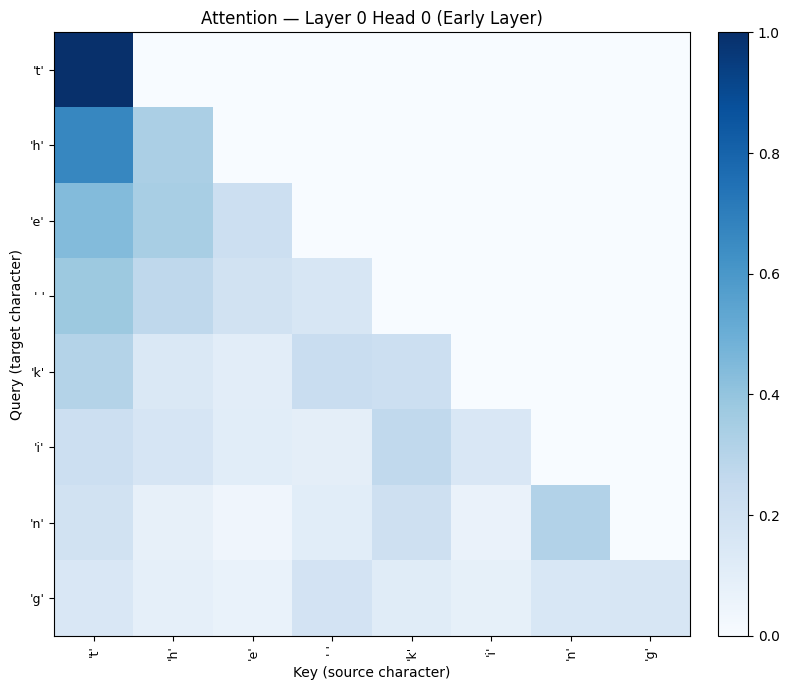

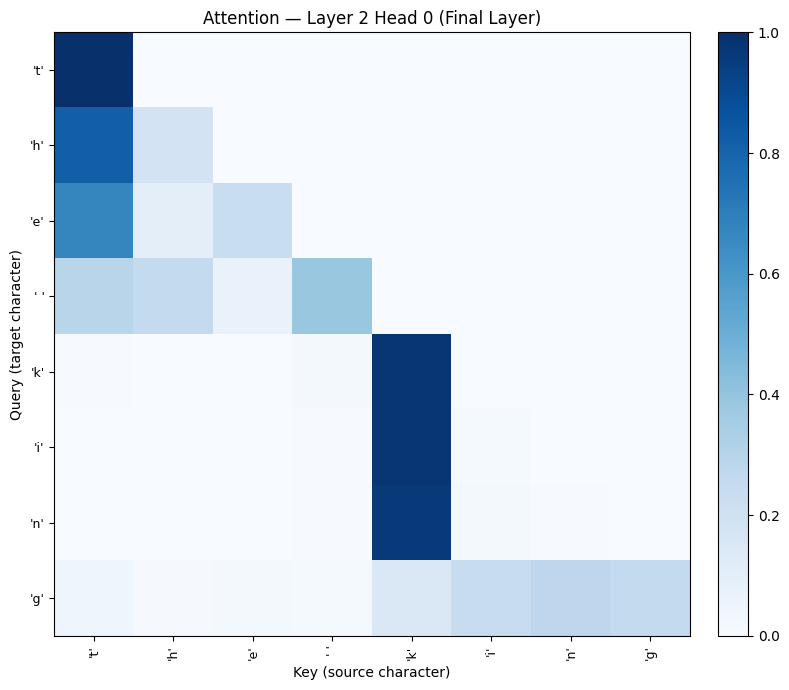

In [8]:
def get_attention_weights(model, text, layer_idx=0, head_idx=0):
    """
    Extract attention weight matrix from a specific layer and head.
    Returns: (T, T) attention matrix and list of characters
    """
    model.eval()
    tokens = encode(text)
    T      = len(tokens)
    idx    = torch.tensor(tokens, dtype=torch.long,
                           device=device).unsqueeze(0)
    with torch.no_grad():
        model(idx)   # forward pass populates attn_weights

    # attn_weights shape: (B, n_heads, T, T)
    attn = model.blocks[layer_idx].attn.attn_weights
    attn = attn[0, head_idx, :T, :T].cpu().numpy()  # (T, T)
    chars = list(text)
    return attn, chars


def plot_attention(attn, chars, title):
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(attn, cmap='Blues', aspect='auto')
    ax.set_xticks(range(len(chars)))
    ax.set_yticks(range(len(chars)))
    ax.set_xticklabels([repr(c) for c in chars], rotation=90, fontsize=9)
    ax.set_yticklabels([repr(c) for c in chars], fontsize=9)
    ax.set_xlabel('Key (source character)')
    ax.set_ylabel('Query (target character)')
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig(f'{title.replace(" ", "_")}.png', dpi=150, bbox_inches='tight')
    plt.show()


input_text = 'the king'

# Layer 0 (first layer), Head 0
attn_l0, chars = get_attention_weights(model_pre, input_text,
                                        layer_idx=0, head_idx=0)
plot_attention(attn_l0, chars,
               'Attention — Layer 0 Head 0 (Early Layer)')

# Layer 2 (last layer), Head 0
attn_l2, chars = get_attention_weights(model_pre, input_text,
                                        layer_idx=2, head_idx=0)
plot_attention(attn_l2, chars,
               'Attention — Layer 2 Head 0 (Final Layer)')

**Attention Heatmap Analysis (3B.4d):**

The two heatmaps for "the king" reveal distinctly different attention
behaviors across layers.

In **Layer 0 (early layer)**, the attention pattern shows a clear
**staircase/diagonal structure** — each query character attends most
strongly to its immediately preceding 1-2 characters, with attention
weight decreasing smoothly as we move further left. For example, 'h'
attends primarily to 't', 'e' attends to 'h' and 't', and the space
character attends to 'e' and 'h'. This confirms that early-layer heads
learn **local positional dependencies** — essentially learning
character-level bigram and trigram patterns. No character attends
strongly to distant positions.

In **Layer 2 (final layer)**, the pattern changes dramatically. The most
striking feature is that **'k' (in "king") attends with very high weight
to itself and the space before it**, rather than distributing attention
locally. This suggests the final layer has learned that word boundaries
and the first character of a word ("k" starting "king") are semantically
significant positions that require strong self-attention. Additionally,
'i', 'n', 'g' all show strong concentrated attention on 'k' — the
entire word "king" appears to be anchored to its first character in the
final layer's representation.

This layer-wise progression — from smooth local staircase patterns in
Layer 0 to sharp, semantically-anchored patterns in Layer 2 — confirms
that our 3-layer Transformer learns a meaningful representational
hierarchy: early layers handle sequential character patterns while later
layers capture higher-level token and word-boundary structure.